In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# 1. PATH CONFIGURATION & IMPORTS
# =========================================================================
tools_path = "/Users/ebennett/Library/CloudStorage/Dropbox-EMI/Evelyn Bennett/misc_project/m70/m70project/ultrasuite-tools-master/ustools"
if tools_path not in sys.path:
    sys.path.append(tools_path)

from core import UltraSuiteCore
from transform_ultrasound import transform_ultrasound

# =========================================================================
# 2. DATA LOCATION SETUP
# =========================================================================
input_path = "/Users/ebennett/Library/CloudStorage/Dropbox-EMI/Evelyn Bennett/misc_project/m70/m70project/ultrasuite-tools-master/ultrasuite_subset"
file = "121_aud"

print(f"Loading data for: {file}...")
data = UltraSuiteCore(directory=input_path, file_basename=file)

if data.ult.size == 0:
    raise FileNotFoundError(f"Could not load data. Ensure {file}.ult exists in {input_path}")

# =========================================================================
# 3. GEOMETRIC TRANSFORMATION
# =========================================================================
frame_idx = 315
raw_frame = data.ult[frame_idx]

transformed_data = transform_ultrasound(
    raw_frame, 
    num_scanlines=data.params['num_scanlines'],
    size_scanline=data.params['size_scanline'],
    angle=data.params['angle'],
    zero_offset=data.params['zero_offset'],
    pixels_per_mm=3
)
corrected_img = transformed_data[0]

# =========================================================================
# 4. 2D FOURIER ANALYSIS & 1D RADIAL DISTRIBUTION
# =========================================================================
# Compute 2D Fourier Transform
f_transform = np.fft.fft2(corrected_img)
f_shift = np.fft.fftshift(f_transform)
magnitude_2d = np.abs(f_shift)

# Calculate the center coordinates of the 2D Fourier spectrum
center_y, center_x = np.array(magnitude_2d.shape) // 2

# Create a coordinate grid containing distances from the center point
y_indices, x_indices = np.indices(magnitude_2d.shape)
r_grid = np.sqrt((x_indices - center_x)**2 + (y_indices - center_y)**2)
r_grid = r_grid.astype(int)

# Bin the pixels by their radial distance to find the average energy per frequency band
max_radius = r_grid.max()
radial_profile = np.zeros(max_radius + 1)

for r in range(max_radius + 1):
    mask = (r_grid == r)
    if mask.any():
        radial_profile[r] = magnitude_2d[mask].mean()

# Convert both spectrum elements to a log scale for visual readability
magnitude_2d_log = np.log(magnitude_2d + 1)
radial_profile_log = np.log(radial_profile + 1)

# =========================================================================
# 5. THREE-PANEL SIDE-BY-SIDE PLOTTING
# =========================================================================
# --- FIGURE 1: Spatial Image and 2D Fourier Spectrum Side-by-Side ---
# Tightened canvas width to 8 inches to match the narrow shape of the wedges
# --- FIGURE 1: Spatial Image and 2D Fourier Spectrum Side-by-Side --

# Panel 1: Real-world Proportion Wedge Image
# --- FIGURE 1: Spatial Image and 2D Fourier Spectrum Side-by-Side ---
# Tightened canvas width to 8 inches to match the narrow shape of the wedges
fig1, axes1 = plt.subplots(1, 2, figsize=(8, 4.8))

# Panel 1: Real-world Proportion Wedge Image
axes1[0].imshow(corrected_img, cmap='gray', aspect='equal')
axes1[0].set_title(f"Ultrasound Frame {frame_idx}\n(Real-World)")
axes1[0].set_xlabel("X (Pixels)")
axes1[0].set_ylabel("Y (Pixels)")

# Panel 2: 2D Fourier Magnitude Spectrum
axes1[1].imshow(magnitude_2d_log, cmap='gray', aspect='equal')
axes1[1].set_title("2D FFT Spectrum\n(Log-Scale)")
axes1[1].set_xlabel("Frequency (Horizontal)")
# Removing the Y-axis label on panel 2 removes the empty text padding buffer

# Force the layout to use absolute zero horizontal spacing between subplots
fig1.subplots_adjust(wspace=0.05, left=0.08, right=0.95, bottom=0.15, top=0.85)


# Panel 2: 2D Fourier Magnitude Spectrum
axes1[1].imshow(magnitude_2d_log, cmap='gray')
axes1[1].set_title("2D FFT Magnitude Spectrum\n(Grayscale Log-Scale)")
axes1[1].set_xlabel("Frequency (Horizontal)")
axes1[1].set_ylabel("Frequency (Vertical)")

fig1.tight_layout()


# --- FIGURE 2: Standalone 1D Frequency Distribution Profile ---
plt.figure(figsize=(8, 4.5))

plt.plot(radial_profile_log, color='black', linewidth=2)
plt.title("Overall Frequency Distribution", fontsize=13, fontweight='semibold')
plt.xlabel("Spatial Frequency (Radial Pixel Distance from Center)", fontsize=11)
plt.ylabel("Log Magnitude (Energy)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

# Render both windows/plots
plt.show()

Loading data for: 121_aud...


FileNotFoundError: [Errno 2] No such file or directory: '/Users/ebennett/Library/CloudStorage/Dropbox-EMI/Evelyn Bennett/misc_project/m70/m70project/ultrasuite-tools-master/ultrasuite_subset/121_aud.txt'

In [ ]:
# flipping the y axis to the bottom
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# 1. PATH CONFIGURATION & IMPORTS
# =========================================================================
tools_path = "/Users/ebennett/Library/CloudStorage/Dropbox-EMI/Evelyn Bennett/misc_project/m70/m70project/ultrasuite-tools-master/ustools"
if tools_path not in sys.path:
    sys.path.append(tools_path)

from core import UltraSuiteCore
from transform_ultrasound import transform_ultrasound

# =========================================================================
# 2. DATA LOCATION SETUP
# =========================================================================
input_path = "/Users/ebennett/Library/CloudStorage/Dropbox-EMI/Evelyn Bennett/misc_project/m70/m70project/ultrasuite-tools-master/ultrasuite_subset"
file = "028_whi"

print(f"Loading data for: {file}...")
data = UltraSuiteCore(directory=input_path, file_basename=file)

if data.ult.size == 0:
    raise FileNotFoundError(f"Could not load data. Ensure {file}.ult exists in {input_path}")

# =========================================================================
# 3. GEOMETRIC TRANSFORMATION
# =========================================================================
frame_idx = 315
raw_frame = data.ult[frame_idx]

transformed_data = transform_ultrasound(
    raw_frame, 
    num_scanlines=data.params['num_scanlines'],
    size_scanline=data.params['size_scanline'],
    angle=data.params['angle'],
    zero_offset=data.params['zero_offset'],
    pixels_per_mm=3
)
corrected_img = transformed_data[0]

# =========================================================================
# 4. 2D FOURIER ANALYSIS & 1D RADIAL DISTRIBUTION
# =========================================================================
# Flip the image vertically before FFT so its spatial matrix matches the 
# bottom-up coordinate system requested for the plots
fft_target_img = np.flipud(corrected_img)

# Compute 2D Fourier Transform
f_transform = np.fft.fft2(fft_target_img)
f_shift = np.fft.fftshift(f_transform)
magnitude_2d = np.abs(f_shift)

# Calculate the center coordinates of the 2D Fourier spectrum
center_y, center_x = np.array(magnitude_2d.shape) // 2

# Create a coordinate grid containing distances from the center point
y_indices, x_indices = np.indices(magnitude_2d.shape)
r_grid = np.sqrt((x_indices - center_x)**2 + (y_indices - center_y)**2)
r_grid = r_grid.astype(int)

# Bin the pixels by their radial distance to find the average energy per frequency band
max_radius = r_grid.max()
radial_profile = np.zeros(max_radius + 1)

for r in range(max_radius + 1):
    mask = (r_grid == r)
    if mask.any():
        radial_profile[r] = magnitude_2d[mask].mean()

# Convert both spectrum elements to a log scale for visual readability
magnitude_2d_log = np.log(magnitude_2d + 1)
radial_profile_log = np.log(radial_profile + 1)

# =========================================================================
# 5. SPLIT PLOTTING (Y-AXIS 0 AT BOTTOM)
# =========================================================================

# --- FIGURE 1: Spatial Image and 2D Fourier Spectrum Side-by-Side ---
fig1, axes1 = plt.subplots(1, 2, figsize=(8, 4.8))

# Panel 1: Real-world Proportion Wedge Image (origin='lower' puts 0 at the bottom)
axes1[0].imshow(corrected_img, cmap='gray', aspect='equal', origin='lower')
axes1[0].set_title(f"Ultrasound Frame {frame_idx}\n(Real-World)")
axes1[0].set_xlabel("X (Pixels)")
axes1[0].set_ylabel("Y (Pixels)")

# Panel 2: 2D Fourier Magnitude Spectrum (origin='lower' puts 0 at the bottom)
axes1[1].imshow(magnitude_2d_log, cmap='gray', aspect='equal', origin='lower')
axes1[1].set_title("2D FFT Spectrum\n(Log-Scale)")
axes1[1].set_xlabel("Frequency (Horizontal)")
axes1[1].set_ylabel("Frequency (Vertical)")

# Pull the two images close together using your preferred tight layout adjustment
fig1.subplots_adjust(wspace=0.05, left=0.08, right=0.95, bottom=0.15, top=0.85)


# --- FIGURE 2: Standalone 1D Frequency Distribution Profile ---
plt.figure(figsize=(8, 4.5))

plt.plot(radial_profile_log, color='black', linewidth=2)
plt.title("Overall Frequency Distribution", fontsize=13, fontweight='semibold')
plt.xlabel("Spatial Frequency (Radial Pixel Distance from Center)", fontsize=11)
plt.ylabel("Log Magnitude (Energy)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

# Render both windows/plots
plt.show()

In [3]:
# 1. Grab the correct ultrasound sampling rate (Frames Per Second)
f_rate = data.params['ult_fps']

# 2. Calculate the index for 9 seconds
target_time = 9.0
nine_sec_index = int(target_time * f_rate)

# 3. Check your array dimensions
total_frames = data.ult.shape[0]

print(f"The ultrasound sampling rate is: {f_rate} frames per second")
print(f"Calculated index for {target_time} seconds: {nine_sec_index}")
print(f"Total available frames in this file: {total_frames}")

if nine_sec_index < total_frames:
    print(f"✓ Success! Use frame_idx = {nine_sec_index} in your script.")
else:
    print(f"⚠ Warning: This recording is only {total_frames / f_rate:.2f} seconds long. "
          f"Index {nine_sec_index} is out of bounds. Using the last frame instead.")

The ultrasound sampling rate is: 81.517 frames per second
Calculated index for 9.0 seconds: 733
Total available frames in this file: 523
⚠ Warning: This recording is only 6.42 seconds long. Index 733 is out of bounds. Using the last frame instead.


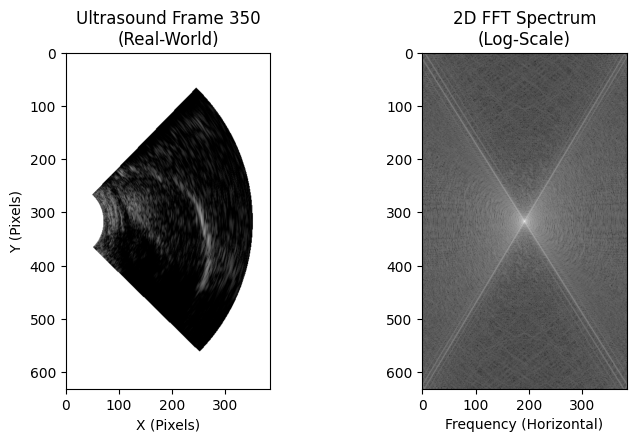

In [9]:
# --- FIGURE 1: Spatial Image and 2D Fourier Spectrum Side-by-Side ---
# Tightened canvas width to 8 inches to match the narrow shape of the wedges
fig1, axes1 = plt.subplots(1, 2, figsize=(8, 4.8))

# Panel 1: Real-world Proportion Wedge Image
axes1[0].imshow(corrected_img, cmap='gray', aspect='equal')
axes1[0].set_title(f"Ultrasound Frame {frame_idx}\n(Real-World)")
axes1[0].set_xlabel("X (Pixels)")
axes1[0].set_ylabel("Y (Pixels)")

# Panel 2: 2D Fourier Magnitude Spectrum
axes1[1].imshow(magnitude_2d_log, cmap='gray', aspect='equal')
axes1[1].set_title("2D FFT Spectrum\n(Log-Scale)")
axes1[1].set_xlabel("Frequency (Horizontal)")
# Removing the Y-axis label on panel 2 removes the empty text padding buffer

# Force the layout to use absolute zero horizontal spacing between subplots
fig1.subplots_adjust(wspace=0.05, left=0.08, right=0.95, bottom=0.15, top=0.85)
